# Univariate Exploratory Data Analysis

## Objective

Analyze class distributions and selected numerical and categorical
features in NSL-KDD and UNSW-NB15.

All visualizations use the original supplied records.
No duplicates are removed.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_dir = current_dir.parent
else:
    project_dir = current_dir

print("Project directory:", project_dir)

Project directory: C:\Users\fatim\Documents\network-intrusion-eda


In [4]:
nsl_columns = [
    "duration", "protocol_type", "service", "flag",
    "src_bytes", "dst_bytes", "land", "wrong_fragment",
    "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted",
    "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate",
    "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    "attack_type", "difficulty_level"
]

nsl_train = pd.read_csv(
    project_dir / "data/raw/nsl_kdd/KDDTrain+.txt",
    header=None,
    names=nsl_columns
)

unsw_train = pd.read_csv(
    project_dir / "data/raw/unsw_nb15/UNSW_NB15_training-set.csv"
)

print("NSL-KDD:", nsl_train.shape)
print("UNSW-NB15:", unsw_train.shape)

NSL-KDD: (125973, 43)
UNSW-NB15: (175341, 45)


In [5]:
nsl_class = (
    nsl_train["attack_type"]
    .eq("normal")
    .map({True: "Normal", False: "Attack"})
)

unsw_class = (
    unsw_train["label"]
    .map({0: "Normal", 1: "Attack"})
)

class_rows = []

for dataset_name, labels in [
    ("NSL-KDD", nsl_class),
    ("UNSW-NB15", unsw_class)
]:
    counts = labels.value_counts()

    for traffic_class in ["Normal", "Attack"]:
        count = int(counts.get(traffic_class, 0))

        class_rows.append({
            "Dataset": dataset_name,
            "Traffic Class": traffic_class,
            "Count": count,
            "Percentage": round(
                count / len(labels) * 100, 2
            )
        })

class_df = pd.DataFrame(class_rows)

display(class_df)

,Dataset,Traffic Class,Count,Percentage
0,NSL-KDD,Normal,67343,53.46
1,NSL-KDD,Attack,58630,46.54
2,UNSW-NB15,Normal,56000,31.94
3,UNSW-NB15,Attack,119341,68.06


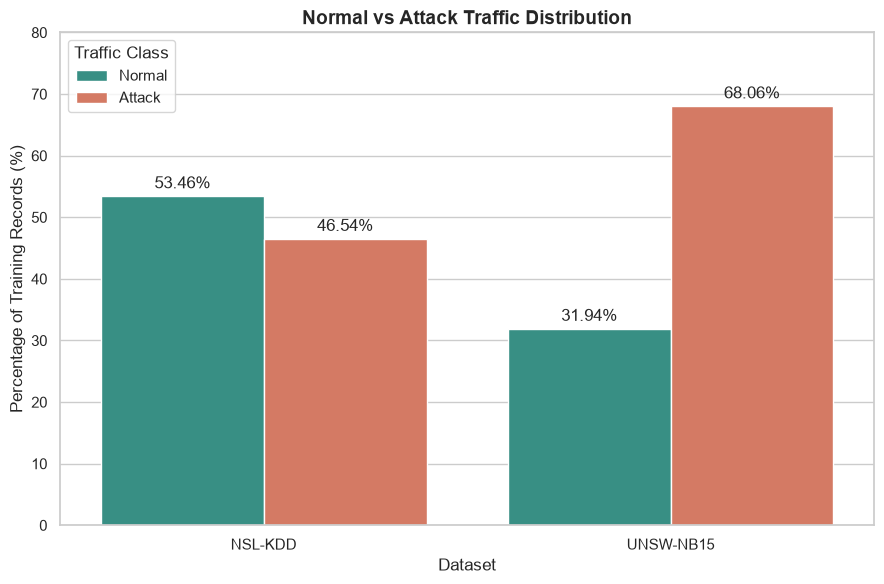

Chart saved: C:\Users\fatim\Documents\network-intrusion-eda\figures\comparative\training_class_distribution.png
File exists: True


In [6]:
plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=class_df,
    x="Dataset",
    y="Percentage",
    hue="Traffic Class",
    hue_order=["Normal", "Attack"],
    palette={
        "Normal": "#2A9D8F",
        "Attack": "#E76F51"
    }
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3
    )

plt.title(
    "Normal vs Attack Traffic Distribution",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Dataset")
plt.ylabel("Percentage of Training Records (%)")
plt.ylim(0, 80)

plt.legend(title="Traffic Class")
plt.tight_layout()

output_path = (
    project_dir
    / "figures"
    / "comparative"
    / "training_class_distribution.png"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", output_path)
print("File exists:", output_path.exists())

In [7]:
percentage_totals = (
    class_df.groupby("Dataset")["Percentage"].sum()
)

print("Percentage totals:")
print(percentage_totals)

assert all(
    abs(total - 100) < 0.02
    for total in percentage_totals
)

assert output_path.exists()

print("\nSUCCESS: Class distribution chart validated!")

Percentage totals:
Dataset
NSL-KDD      100.0
UNSW-NB15    100.0
Name: Percentage, dtype: float64

SUCCESS: Class distribution chart validated!


## M5.2 — Attack Label and Category Distributions

### Objective

Identify frequent and rare attack labels in the NSL-KDD and UNSW-NB15
training partitions.

NSL-KDD attack names and UNSW-NB15 attack categories are analyzed
separately because their taxonomies differ.

In [8]:
nsl_attack_counts = (
    nsl_train.loc[
        nsl_train["attack_type"] != "normal",
        "attack_type"
    ]
    .value_counts()
)

print("Number of distinct attack types:", len(nsl_attack_counts))

display(nsl_attack_counts)

Number of distinct attack types: 22


attack_type
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64

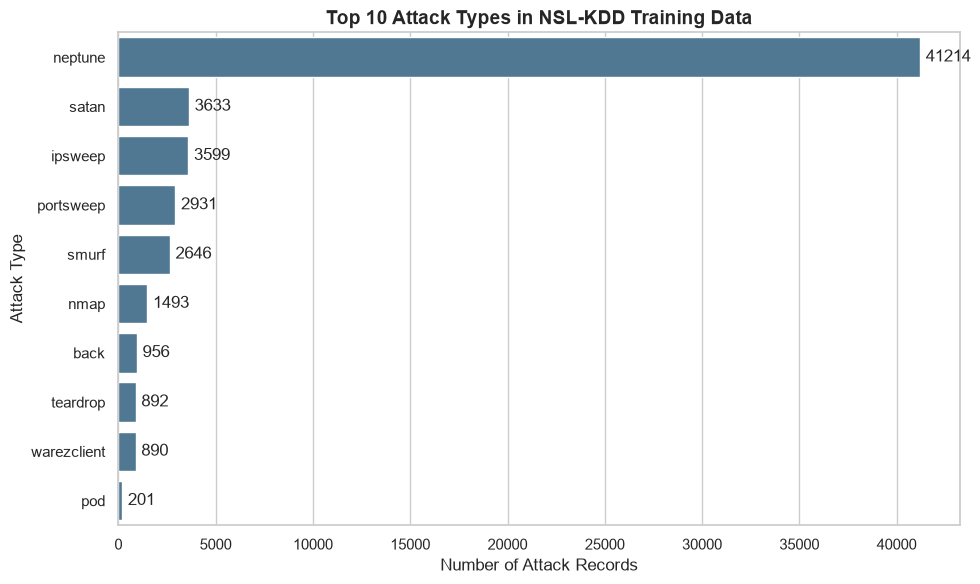

NSL-KDD chart saved: True


In [9]:
nsl_top10 = nsl_attack_counts.head(10)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=nsl_top10.values,
    y=nsl_top10.index,
    color="#457B9D"
)

plt.title(
    "Top 10 Attack Types in NSL-KDD Training Data",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Attack Records")
plt.ylabel("Attack Type")

for container in ax.containers:
    ax.bar_label(container, padding=4)

plt.tight_layout()

nsl_chart_path = (
    project_dir
    / "figures"
    / "univariate"
    / "nsl_kdd_top10_attack_types.png"
)

nsl_chart_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    nsl_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("NSL-KDD chart saved:", nsl_chart_path.exists())

In [11]:
unsw_attack_counts = (
    unsw_train.loc[
        unsw_train["label"] == 1,
        "attack_cat"
    ]
    .value_counts()
)

print("Number of attack categories:", len(unsw_attack_counts))

display(unsw_attack_counts)

Number of attack categories: 9


attack_cat
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

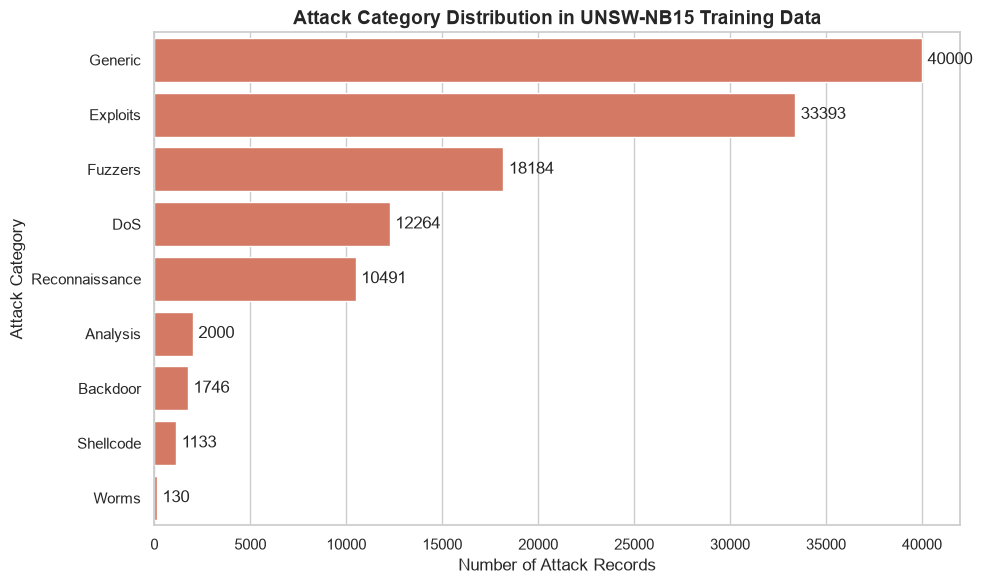

UNSW-NB15 chart saved: True


In [12]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=unsw_attack_counts.values,
    y=unsw_attack_counts.index,
    color="#E76F51"
)

plt.title(
    "Attack Category Distribution in UNSW-NB15 Training Data",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Attack Records")
plt.ylabel("Attack Category")

for container in ax.containers:
    ax.bar_label(container, padding=4)

plt.tight_layout()

unsw_chart_path = (
    project_dir
    / "figures"
    / "univariate"
    / "unsw_nb15_attack_categories.png"
)

unsw_chart_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    unsw_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("UNSW-NB15 chart saved:", unsw_chart_path.exists())

In [13]:
print("UNSW-NB15 attack records:", unsw_attack_counts.sum())

assert unsw_attack_counts.sum() == 119341

print("SUCCESS: UNSW-NB15 attack counts validated!")

UNSW-NB15 attack records: 119341
SUCCESS: UNSW-NB15 attack counts validated!


In [14]:
print("NSL-KDD — Top 5 attack types:")
print(nsl_attack_counts.head(5))

print("\nUNSW-NB15 — All attack categories:")
print(unsw_attack_counts)

print("\nTotal attack records:")
print("NSL-KDD:", nsl_attack_counts.sum())
print("UNSW-NB15:", unsw_attack_counts.sum())

assert nsl_attack_counts.sum() == 58630
assert unsw_attack_counts.sum() == 119341

assert nsl_chart_path.exists()
assert unsw_chart_path.exists()

print("\nSUCCESS: M5.2 validation passed!")

NSL-KDD — Top 5 attack types:
attack_type
neptune      41214
satan         3633
ipsweep       3599
portsweep     2931
smurf         2646
Name: count, dtype: int64

UNSW-NB15 — All attack categories:
attack_cat
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

Total attack records:
NSL-KDD: 58630
UNSW-NB15: 119341

SUCCESS: M5.2 validation passed!


## M5.3 — Numerical Feature Distributions

### Objective

Examine the distributions of selected numerical features in
NSL-KDD and UNSW-NB15.

Focus:
- Central tendency
- Skewness
- Extreme values
- Distribution shape

Original values are preserved.

In [15]:
numerical_features = {
    "NSL-KDD": {
        "data": nsl_train,
        "columns": ["duration", "src_bytes", "dst_bytes"]
    },
    "UNSW-NB15": {
        "data": unsw_train,
        "columns": ["dur", "sbytes", "dbytes"]
    }
}

for dataset_name, info in numerical_features.items():

    print(f"\n{'=' * 50}")
    print(dataset_name)
    print(f"{'=' * 50}")

    summary = info["data"][info["columns"]].describe()

    display(summary)


NSL-KDD


,duration,src_bytes,dst_bytes
count,125973.00000,1.259730e+05,1.259730e+05
mean,287.14465,4.556674e+04,1.977911e+04
std,2604.51531,5.870331e+06,4.021269e+06
min,0.00000,0.000000e+00,0.000000e+00
25%,0.00000,0.000000e+00,0.000000e+00
50%,0.00000,4.400000e+01,0.000000e+00
75%,0.00000,2.760000e+02,5.160000e+02
max,42908.00000,1.379964e+09,1.309937e+09



UNSW-NB15


,dur,sbytes,dbytes
count,175341.000000,1.753410e+05,1.753410e+05
mean,1.359389,8.844844e+03,1.492892e+04
std,6.480249,1.747656e+05,1.436542e+05
min,0.000000,2.800000e+01,0.000000e+00
25%,0.000008,1.140000e+02,0.000000e+00
50%,0.001582,4.300000e+02,1.640000e+02
75%,0.668069,1.418000e+03,1.102000e+03
max,59.999989,1.296523e+07,1.465555e+07


In [16]:
skewness_results = []

for dataset_name, info in numerical_features.items():

    df = info["data"]

    for feature in info["columns"]:

        skewness_results.append({
            "Dataset": dataset_name,
            "Feature": feature,
            "Mean": df[feature].mean(),
            "Median": df[feature].median(),
            "Maximum": df[feature].max(),
            "Skewness": df[feature].skew()
        })

skewness_df = pd.DataFrame(skewness_results)

display(skewness_df.round(3))

,Dataset,Feature,Mean,Median,Maximum,Skewness
0,NSL-KDD,duration,287.145,0.000,4.290800e+04,11.880
1,NSL-KDD,src_bytes,45566.743,44.000,1.379964e+09,190.669
2,NSL-KDD,dst_bytes,19779.114,0.000,1.309937e+09,290.053
3,UNSW-NB15,dur,1.359,0.002,6.000000e+01,7.496
4,UNSW-NB15,sbytes,8844.844,430.000,1.296523e+07,45.303
5,UNSW-NB15,dbytes,14928.919,164.000,1.465555e+07,39.761


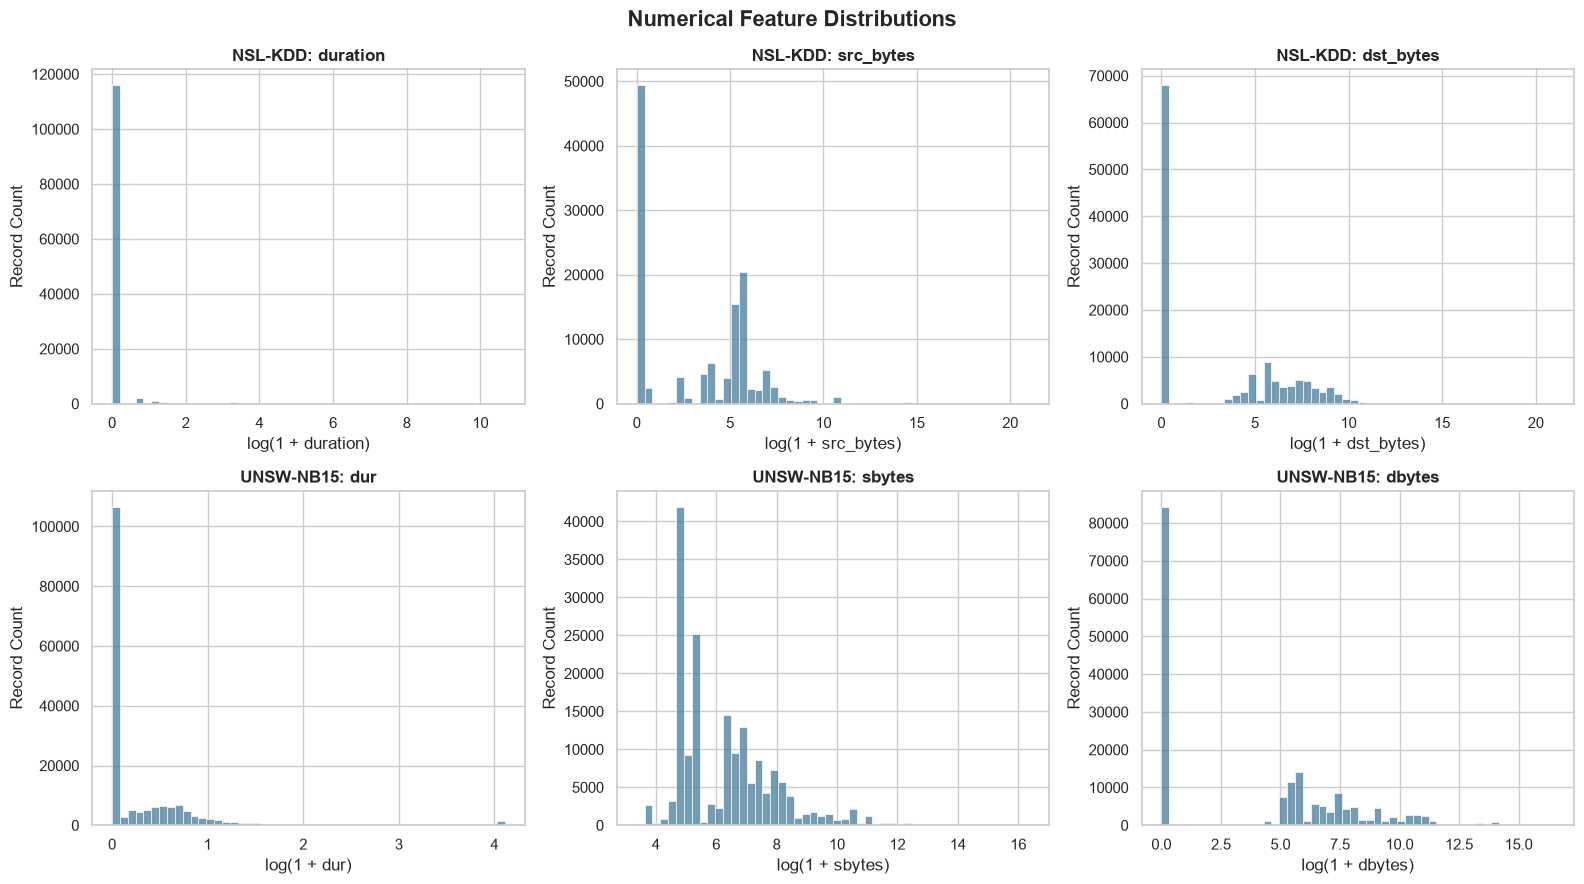

Chart saved: C:\Users\fatim\Documents\network-intrusion-eda\figures\univariate\numerical_feature_distributions.png
File exists: True


In [17]:
import numpy as np

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9)
)

feature_groups = [
    (
        "NSL-KDD",
        nsl_train,
        ["duration", "src_bytes", "dst_bytes"]
    ),
    (
        "UNSW-NB15",
        unsw_train,
        ["dur", "sbytes", "dbytes"]
    )
]

for row_index, (dataset_name, df, features) in enumerate(feature_groups):

    for col_index, feature in enumerate(features):

        ax = axes[row_index, col_index]

        transformed_values = np.log1p(df[feature])

        sns.histplot(
            transformed_values,
            bins=50,
            ax=ax,
            color="#457B9D"
        )

        ax.set_title(
            f"{dataset_name}: {feature}",
            fontweight="bold"
        )

        ax.set_xlabel(f"log(1 + {feature})")
        ax.set_ylabel("Record Count")

plt.suptitle(
    "Numerical Feature Distributions",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

numerical_chart_path = (
    project_dir
    / "figures"
    / "univariate"
    / "numerical_feature_distributions.png"
)

numerical_chart_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    numerical_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", numerical_chart_path)
print("File exists:", numerical_chart_path.exists())

In [18]:
assert numerical_chart_path.exists()

for dataset_name, info in numerical_features.items():

    df = info["data"]

    for feature in info["columns"]:

        assert df[feature].notna().all(), (
            f"Missing values found in {dataset_name}: {feature}"
        )

        assert (df[feature] >= 0).all(), (
            f"Negative values found in {dataset_name}: {feature}"
        )

print("SUCCESS: Numerical feature analysis validated!")

SUCCESS: Numerical feature analysis validated!


## M5.4 — Categorical Feature Distributions

### Objective

Explore the frequency distributions of categorical network traffic
features in NSL-KDD and UNSW-NB15.

The analysis focuses on:
- Protocol types
- Network services
- Connection flags or states

Dataset-specific category definitions are preserved.

In [19]:
categorical_features = {
    "NSL-KDD": {
        "data": nsl_train,
        "columns": ["protocol_type", "service", "flag"]
    },
    "UNSW-NB15": {
        "data": unsw_train,
        "columns": ["proto", "service", "state"]
    }
}

category_summary = []

for dataset_name, info in categorical_features.items():

    df = info["data"]

    for feature in info["columns"]:

        category_summary.append({
            "Dataset": dataset_name,
            "Feature": feature,
            "Unique Categories": df[feature].nunique(),
            "Most Common Category": df[feature].mode()[0],
            "Most Common Count": df[feature].value_counts().iloc[0]
        })

category_summary_df = pd.DataFrame(category_summary)

display(category_summary_df)

,Dataset,Feature,Unique Categories,Most Common Category,Most Common Count
0,NSL-KDD,protocol_type,3,tcp,102689
1,NSL-KDD,service,70,http,40338
2,NSL-KDD,flag,11,SF,74945
3,UNSW-NB15,proto,133,tcp,79946
4,UNSW-NB15,service,13,-,94168
5,UNSW-NB15,state,9,INT,82275


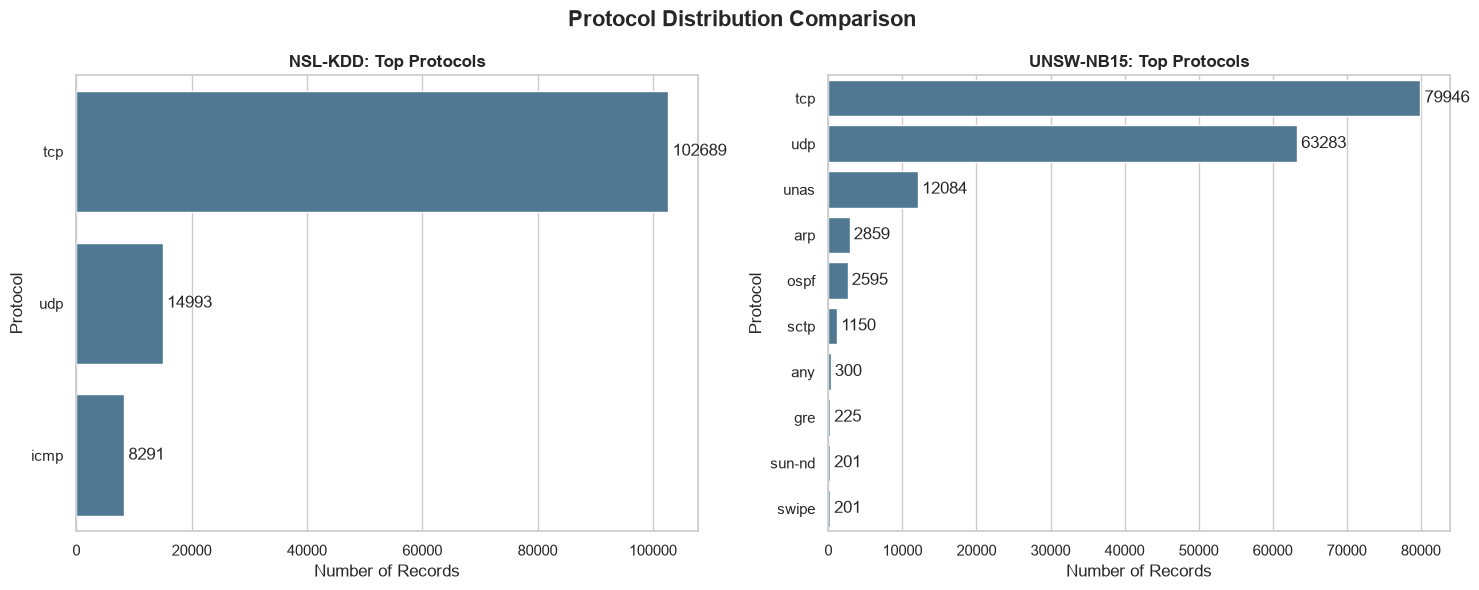

Protocol chart saved: True


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

protocol_configs = [
    ("NSL-KDD", nsl_train, "protocol_type"),
    ("UNSW-NB15", unsw_train, "proto")
]

for ax, (dataset_name, df, feature) in zip(axes, protocol_configs):

    counts = df[feature].value_counts().head(10)

    sns.barplot(
        x=counts.values,
        y=counts.index,
        ax=ax,
        color="#457B9D"
    )

    ax.set_title(
        f"{dataset_name}: Top Protocols",
        fontweight="bold"
    )

    ax.set_xlabel("Number of Records")
    ax.set_ylabel("Protocol")

    for container in ax.containers:
        ax.bar_label(container, padding=3)

plt.suptitle(
    "Protocol Distribution Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

protocol_chart_path = (
    project_dir
    / "figures"
    / "univariate"
    / "protocol_distributions.png"
)

protocol_chart_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    protocol_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Protocol chart saved:", protocol_chart_path.exists())

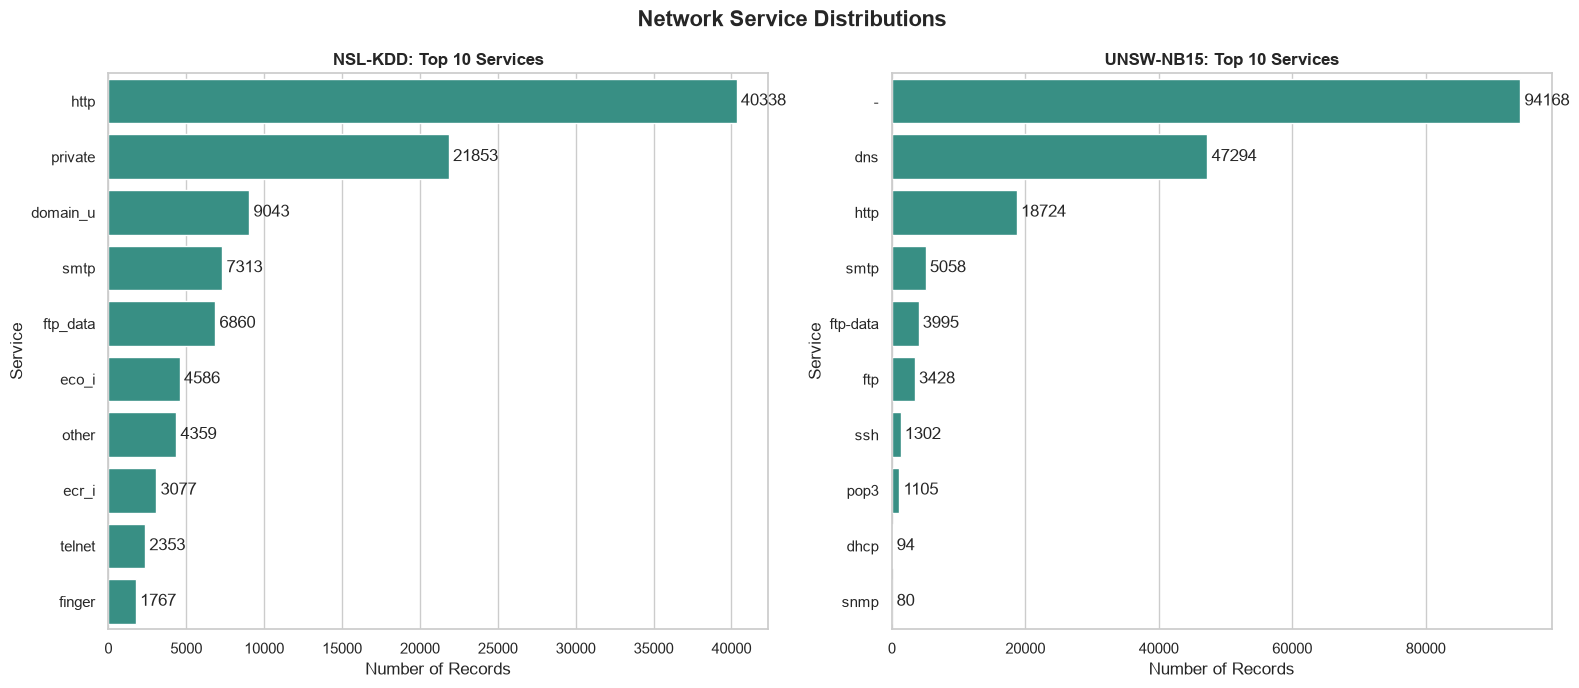

Service chart saved: True


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

service_configs = [
    ("NSL-KDD", nsl_train, "service"),
    ("UNSW-NB15", unsw_train, "service")
]

for ax, (dataset_name, df, feature) in zip(axes, service_configs):

    counts = df[feature].value_counts().head(10)

    sns.barplot(
        x=counts.values,
        y=counts.index,
        ax=ax,
        color="#2A9D8F"
    )

    ax.set_title(
        f"{dataset_name}: Top 10 Services",
        fontweight="bold"
    )

    ax.set_xlabel("Number of Records")
    ax.set_ylabel("Service")

    for container in ax.containers:
        ax.bar_label(container, padding=3)

plt.suptitle(
    "Network Service Distributions",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

service_chart_path = (
    project_dir
    / "figures"
    / "univariate"
    / "service_distributions.png"
)

service_chart_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    service_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Service chart saved:", service_chart_path.exists())

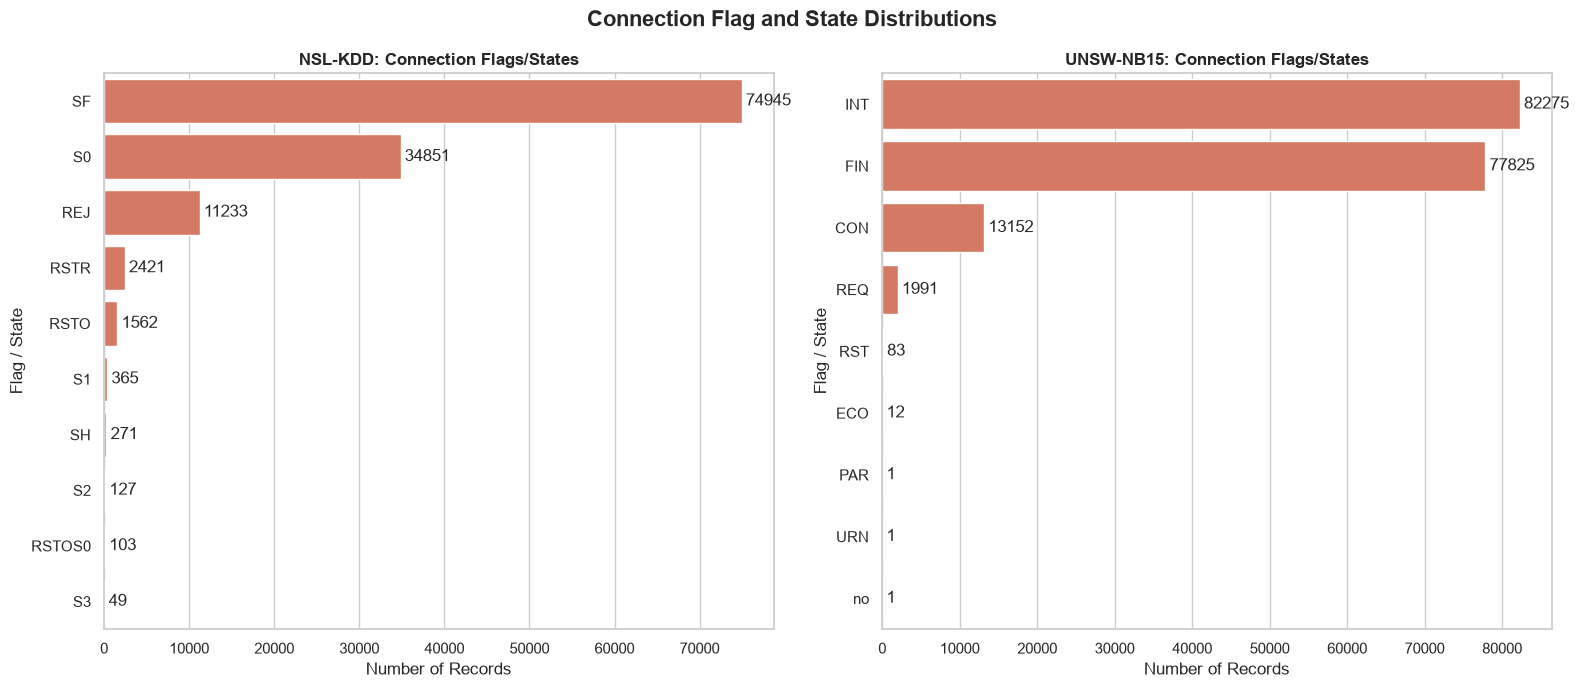

Connection state chart saved: True


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

state_configs = [
    ("NSL-KDD", nsl_train, "flag"),
    ("UNSW-NB15", unsw_train, "state")
]

for ax, (dataset_name, df, feature) in zip(axes, state_configs):

    counts = df[feature].value_counts().head(10)

    sns.barplot(
        x=counts.values,
        y=counts.index,
        ax=ax,
        color="#E76F51"
    )

    ax.set_title(
        f"{dataset_name}: Connection Flags/States",
        fontweight="bold"
    )

    ax.set_xlabel("Number of Records")
    ax.set_ylabel("Flag / State")

    for container in ax.containers:
        ax.bar_label(container, padding=3)

plt.suptitle(
    "Connection Flag and State Distributions",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

state_chart_path = (
    project_dir
    / "figures"
    / "univariate"
    / "connection_state_distributions.png"
)

state_chart_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    state_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Connection state chart saved:", state_chart_path.exists())

In [24]:
chart_paths = [
    protocol_chart_path,
    service_chart_path,
    state_chart_path
]

for path in chart_paths:
    assert path.exists(), f"Missing chart: {path}"

for dataset_name, info in categorical_features.items():

    df = info["data"]

    for feature in info["columns"]:

        assert df[feature].notna().all(), (
            f"Missing values in {dataset_name}: {feature}"
        )

        assert df[feature].nunique() > 0, (
            f"No categories found in {dataset_name}: {feature}"
        )

print("SUCCESS: Categorical feature analysis validated!")

SUCCESS: Categorical feature analysis validated!
